--- Аналитический расчет для источника в центре ---
Ожидаемый средний заряд (с учетом затухания): 97.35 ф.э.

Запуск сэмплинга отклика детектора в PyMC...
Генерация референтного спектра методом прямого Монте-Карло...

================ СРАВНЕНИЕ РЕЗУЛЬТАТОВ ================
PyMC Модель:     Среднее = 97.20 ф.э. | СКО = 9.49 ф.э.
Прямой Монте-Карло: Среднее = 97.52 ф.э. | СКО = 12.10 ф.э.


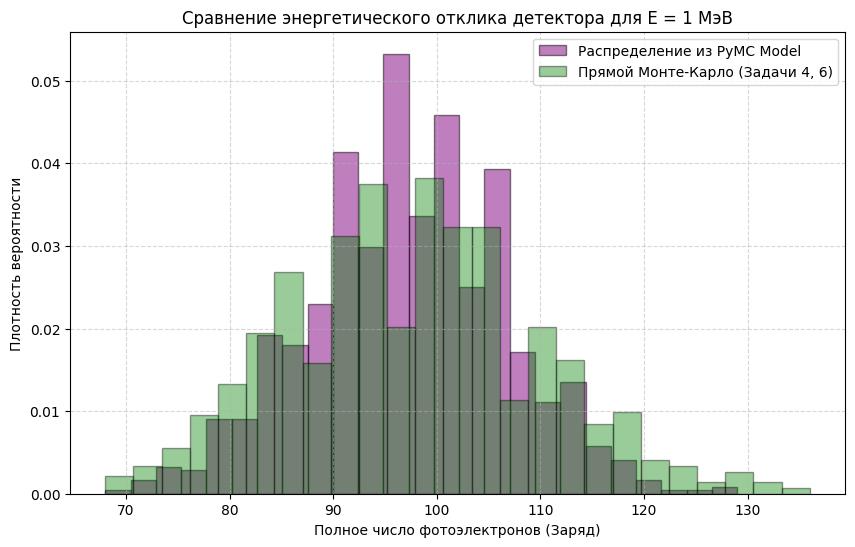

In [ ]:
import numpy as np
import pymc as pm
import matplotlib.pyplot as plt

R = 2.0
N = 40
r = 0.1
a = 0.5
Y = 10000
E_true = 1.0
lambda_att = 8.0

# 1. Аналитический расчёт параметров для центра сферы
p_geom = (r**2) / (4.0 * R**2)
p_attenuation = np.exp(-R / lambda_att)
p_single_pmt = p_geom * p_attenuation * a
p_total_detection = N * p_single_pmt
expected_mu = E_true * Y * p_total_detection

print("--- Аналитический расчёт для источника в центре ---")
print(f"Ожидаемый средний заряд с учётом затухания: {expected_mu:.2f} ф.э.\n")

# 2. Вероятностная модель в PyMC
with pm.Model() as detector_model:
    E = pm.Data("Energy", E_true)
    mu_photons = E * Y
    mu_photoelectrons = mu_photons * p_total_detection
    Q = pm.Poisson("Total_Photoelectrons", mu=mu_photoelectrons)

# 3. Генерация отклика (из априорного предиктивного распределения)
print("Запуск отклика детектора в PyMC")
with detector_model:
    prior_predictive = pm.sample_prior_predictive(samples=1000, random_seed=42)

if "prior" in prior_predictive:
    pymc_charges = prior_predictive.prior["Total_Photoelectrons"].values.flatten()
else:
    pymc_charges = prior_predictive.prior_predictive["Total_Photoelectrons"].values.flatten()


# 4. Сравнение с результатами симуляции из задач 4, 6
print("Генерация референтного спектра методом прямого Монте-Карло")
mc_charges = []
for _ in range(1000):
    n_ph = np.random.poisson(lam=E_true * Y)
    survived = np.random.uniform(0, 1, n_ph) < np.exp(-R / lambda_att)
    n_survived = np.sum(survived)

    p_hit_any_pmt = N * (r**2) / (4.0 * R**2)
    hits = np.random.uniform(0, 1, n_survived) < p_hit_any_pmt
    n_hits = np.sum(hits)

    pe = np.random.poisson(lam=a, size=n_hits)
    mc_charges.append(np.sum(pe))

mc_charges = np.array(mc_charges)

print("\n================ СРАВНЕНИЕ РЕЗУЛЬТАТОВ ================")
print(f"PyMC Модель:     среднее = {np.mean(pymc_charges):.2f} ф.э. | СКО = {np.std(pymc_charges):.2f} ф.э.")
print(f"Прямой Монте-Карло: среднее = {np.mean(mc_charges):.2f} ф.э. | СКО = {np.std(mc_charges):.2f} ф.э.")
print("=======================================================")

plt.figure(figsize=(10, 6))
plt.hist(pymc_charges, bins=25, alpha=0.5, color='purple', label='Распределение из PyMC', edgecolor='black', density=True)
plt.hist(mc_charges, bins=25, alpha=0.4, color='green', label='Прямой Монте-Карло (задачи 4, 6)', edgecolor='black', density=True)
plt.title("Сравнение энергетического отклика детектора для E = 1 МэВ")
plt.xlabel("Полное число фотоэлектронов (заряд)")
plt.ylabel("Плотность вероятности")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()
